<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/solutions/Session15_autoencoders_and_vae_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۱۵: Autoencoder و Variational Autoencoder

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session15_autoencoders_and_vae.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

> **نکتهٔ اجرا:** بعضی پاسخ‌ها مدل‌های بزرگ‌تری آموزش می‌دهند؛ در Colab از منوی `Runtime → Change runtime type` گزینهٔ **T4 GPU** را انتخاب کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import roc_auc_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
tf = transforms.ToTensor()
train_set = datasets.FashionMNIST('data', train=True, download=True, transform=tf)
test_set = datasets.FashionMNIST('data', train=False, download=True, transform=tf)
CLASSES = train_set.classes
train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2)
test_loader = DataLoader(test_set, batch_size=512, num_workers=2)
EPOCHS = 10 if device.type == 'cuda' else 5            # fewer epochs on CPU


class Encoder(nn.Module):
    def __init__(self, latent, out_mult=1):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(1, 32, 3, stride=2, padding=1), nn.ReLU(),
                                  nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(), nn.Flatten())
        self.fc = nn.Linear(64 * 7 * 7, latent * out_mult)

    def forward(self, x):
        return self.fc(self.conv(x))


class Decoder(nn.Module):
    def __init__(self, latent):
        super().__init__()
        self.fc = nn.Linear(latent, 64 * 7 * 7)
        self.deconv = nn.Sequential(nn.ReLU(), nn.Unflatten(1, (64, 7, 7)),
                                    nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1), nn.ReLU(),
                                    nn.ConvTranspose2d(32, 1, 4, stride=2, padding=1), nn.Sigmoid())

    def forward(self, z):
        return self.deconv(self.fc(z))


class Autoencoder(nn.Module):
    def __init__(self, latent=16):
        super().__init__()
        self.encoder, self.decoder = Encoder(latent), Decoder(latent)

    def forward(self, x):
        return self.decoder(self.encoder(x))


class VAE(nn.Module):
    def __init__(self, latent=16):
        super().__init__()
        self.latent = latent
        self.encoder, self.decoder = Encoder(latent, out_mult=2), Decoder(latent)

    def forward(self, x):
        mu, log_var = self.encoder(x).chunk(2, dim=1)
        z = mu + torch.exp(0.5 * log_var) * torch.randn_like(mu)
        return self.decoder(z), mu, log_var


def train_ae(model, loader=train_loader, epochs=EPOCHS, corrupt=None):
    """`corrupt(x)` returns the network input; the target is always the clean x."""
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for _ in range(epochs):
        model.train()
        for x, _ in loader:
            x = x.to(device)
            loss = F.mse_loss(model(corrupt(x) if corrupt else x), x)
            opt.zero_grad(); loss.backward(); opt.step()
    return model


def train_vae(model, epochs=EPOCHS, beta=1.0):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    for _ in range(epochs):
        model.train()
        for x, _ in train_loader:
            x = x.to(device)
            x_hat, mu, log_var = model(x)
            recon = F.binary_cross_entropy(x_hat, x, reduction='sum') / len(x)
            kl = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp()) / len(x)
            loss = recon + beta * kl
            opt.zero_grad(); loss.backward(); opt.step()
    return model


@torch.no_grad()
def test_mse(model):
    model.eval()
    se = 0.0
    for x, _ in test_loader:
        x = x.to(device)
        out = model(x)
        se += F.mse_loss(out[0] if isinstance(out, tuple) else out, x, reduction='sum').item()
    return se / (len(test_set) * 28 * 28)


def show_rows(rows, titles, n=8):
    fig, axes = plt.subplots(len(rows), n, figsize=(1.5 * n, 1.6 * len(rows)))
    for r, (row, title) in enumerate(zip(rows, titles)):
        for c in range(n):
            axes[r, c].imshow(row[c, 0].cpu(), cmap='gray', vmin=0, vmax=1); axes[r, c].axis('off')
        axes[r, 0].set_title(title, fontsize=9, loc='left')
    plt.tight_layout(); plt.show()


x_test = next(iter(test_loader))[0][:8].to(device)

device: cpu


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

Autoencoder را با `LATENT` برابر ۲، ۸ و ۶۴ آموزش دهید و خطای بازسازی و کیفیت تصاویر را مقایسه کنید.

</div>

latent =  2: test reconstruction MSE 0.03280


latent =  8: test reconstruction MSE 0.01548


latent = 64: test reconstruction MSE 0.00668


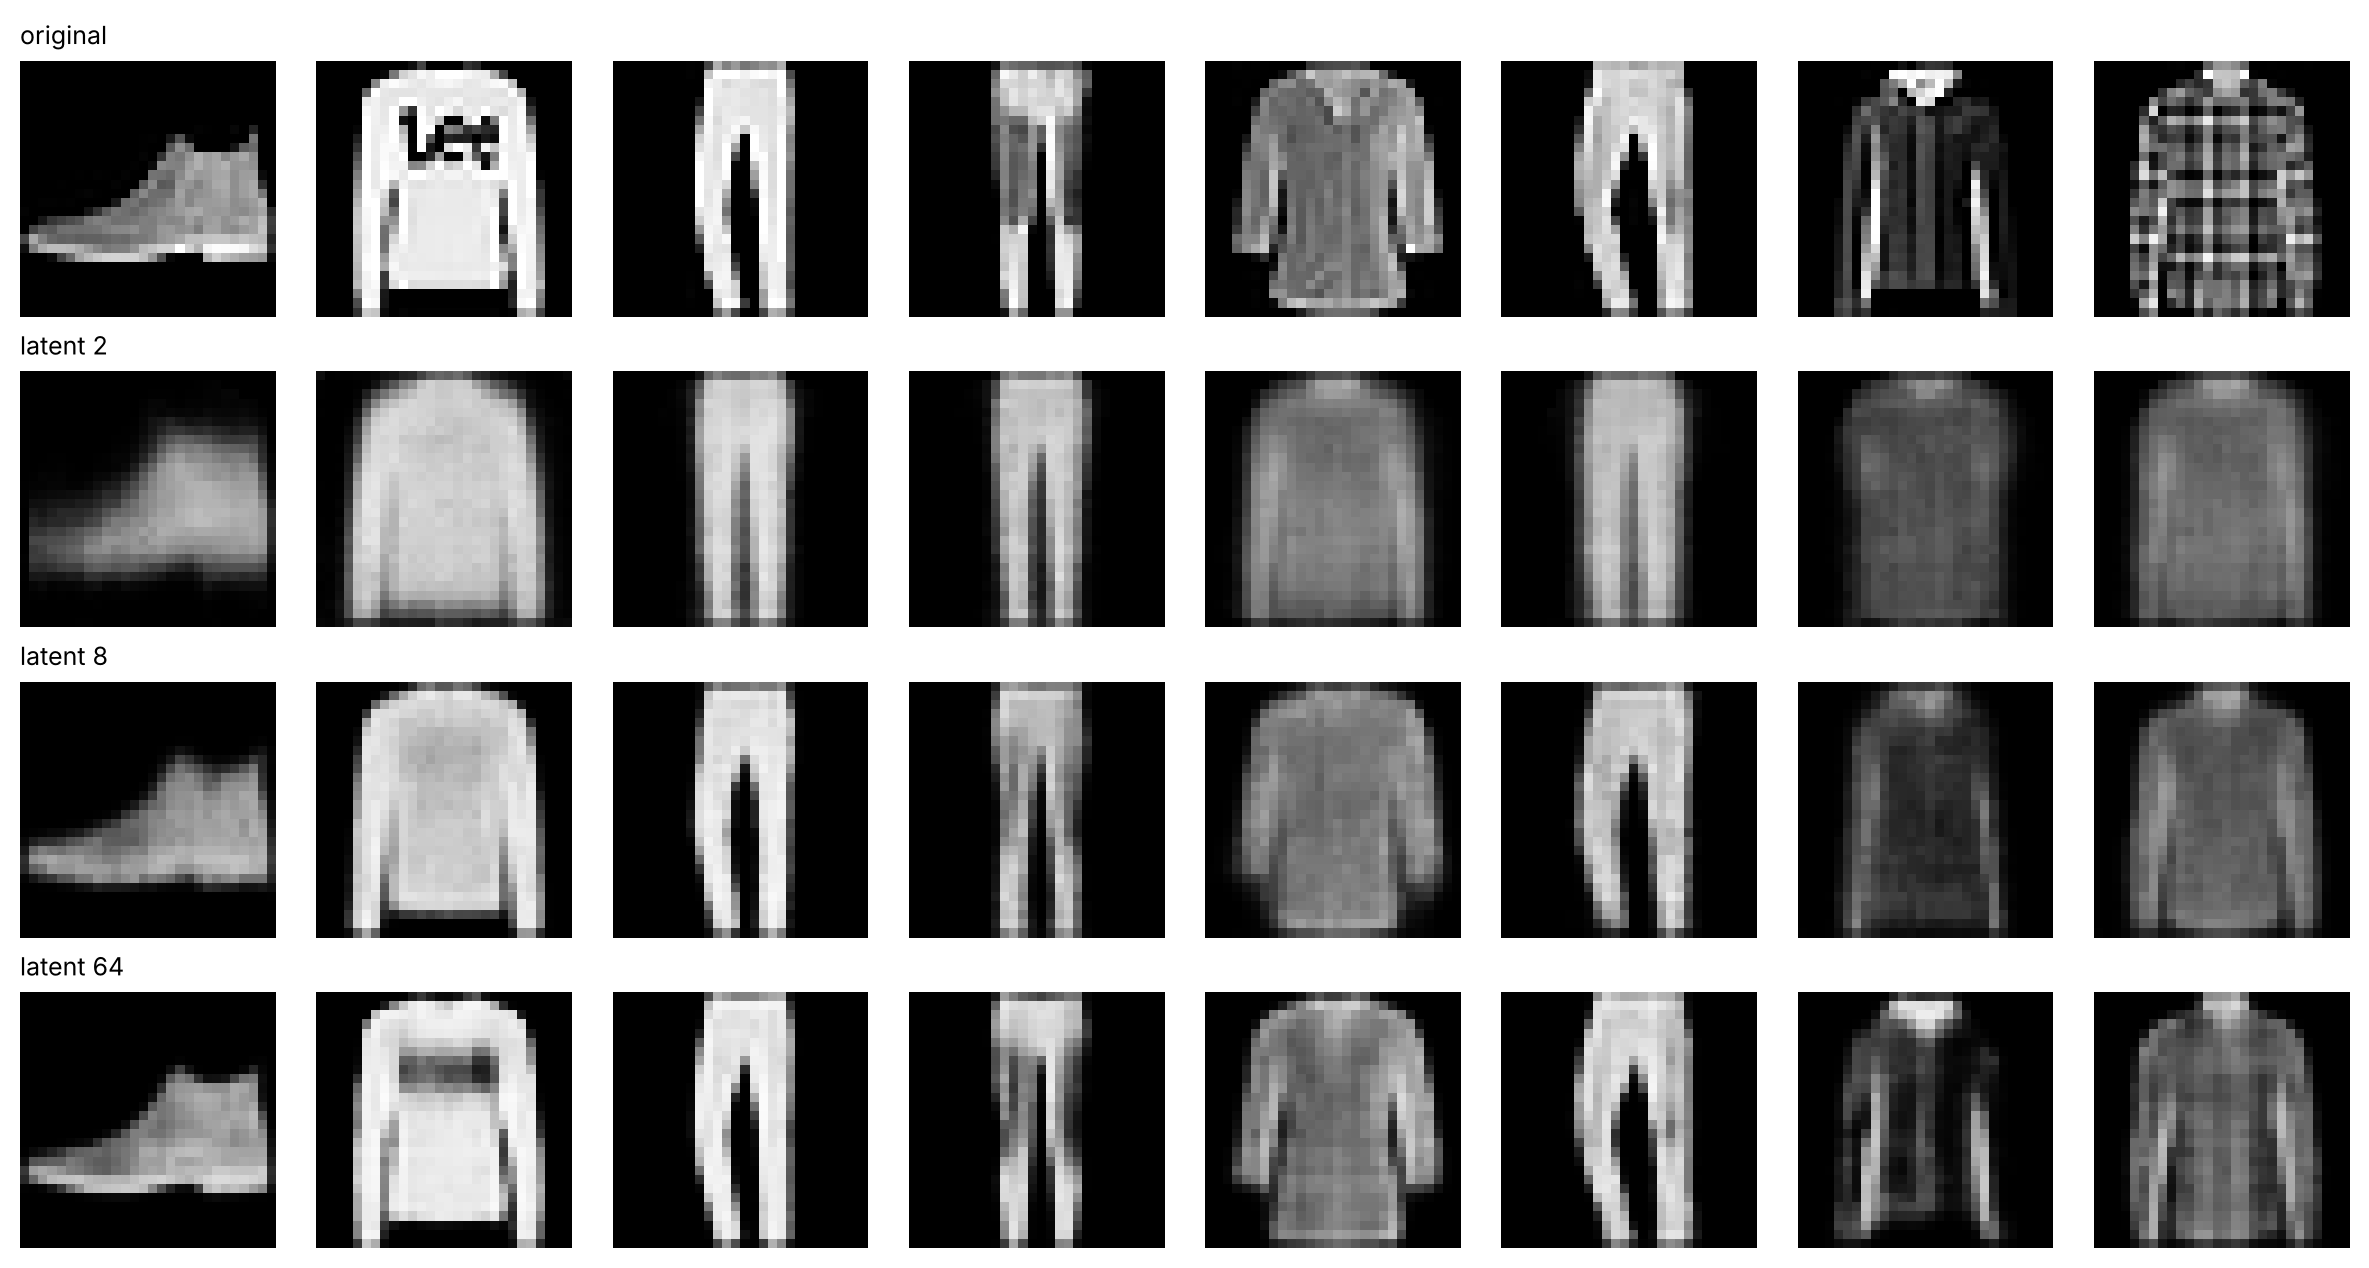

In [2]:
models_by_latent = {}
for latent in (2, 8, 64):
    torch.manual_seed(0)
    models_by_latent[latent] = train_ae(Autoencoder(latent))
    print(f'latent = {latent:2d}: test reconstruction MSE {test_mse(models_by_latent[latent]):.5f}')

with torch.no_grad():
    rows = [x_test] + [models_by_latent[l].eval()(x_test) for l in (2, 8, 64)]
show_rows(rows, ['original', 'latent 2', 'latent 8', 'latent 64'])

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با بعد ۲، شبکه فقط می‌تواند «نوع کلی» شیء را ذخیره کند. بازسازی‌ها بسیار تار و شبیه میانگین یک کلاس‌اند و جزئیاتی مثل طرح روی پیراهن از بین می‌رود. با بعد ۸ شکل و سایه‌روشن کلی حفظ می‌شود. با بعد ۶۴ بازسازی‌ها بسیار نزدیک به اصل‌اند و خطا چند برابر کمتر است. بعد نهان یک **مصالحه** است: هرچه بزرگ‌تر، بازسازی بهتر اما فشرده‌سازی کمتر. اگر بعد نهان به ابعاد ورودی نزدیک شود، Autoencoder می‌تواند تقریباً «کپی» کند و ویژگی معناداری یاد نمی‌گیرد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

یک VAE با فضای نهان **دوبعدی** آموزش دهید و Decoder را روی یک شبکه منظم از نقاط در بازه $[-3, 3]^2$ اجرا کنید تا «نقشه» کامل فضای نهان را ببینید.

</div>

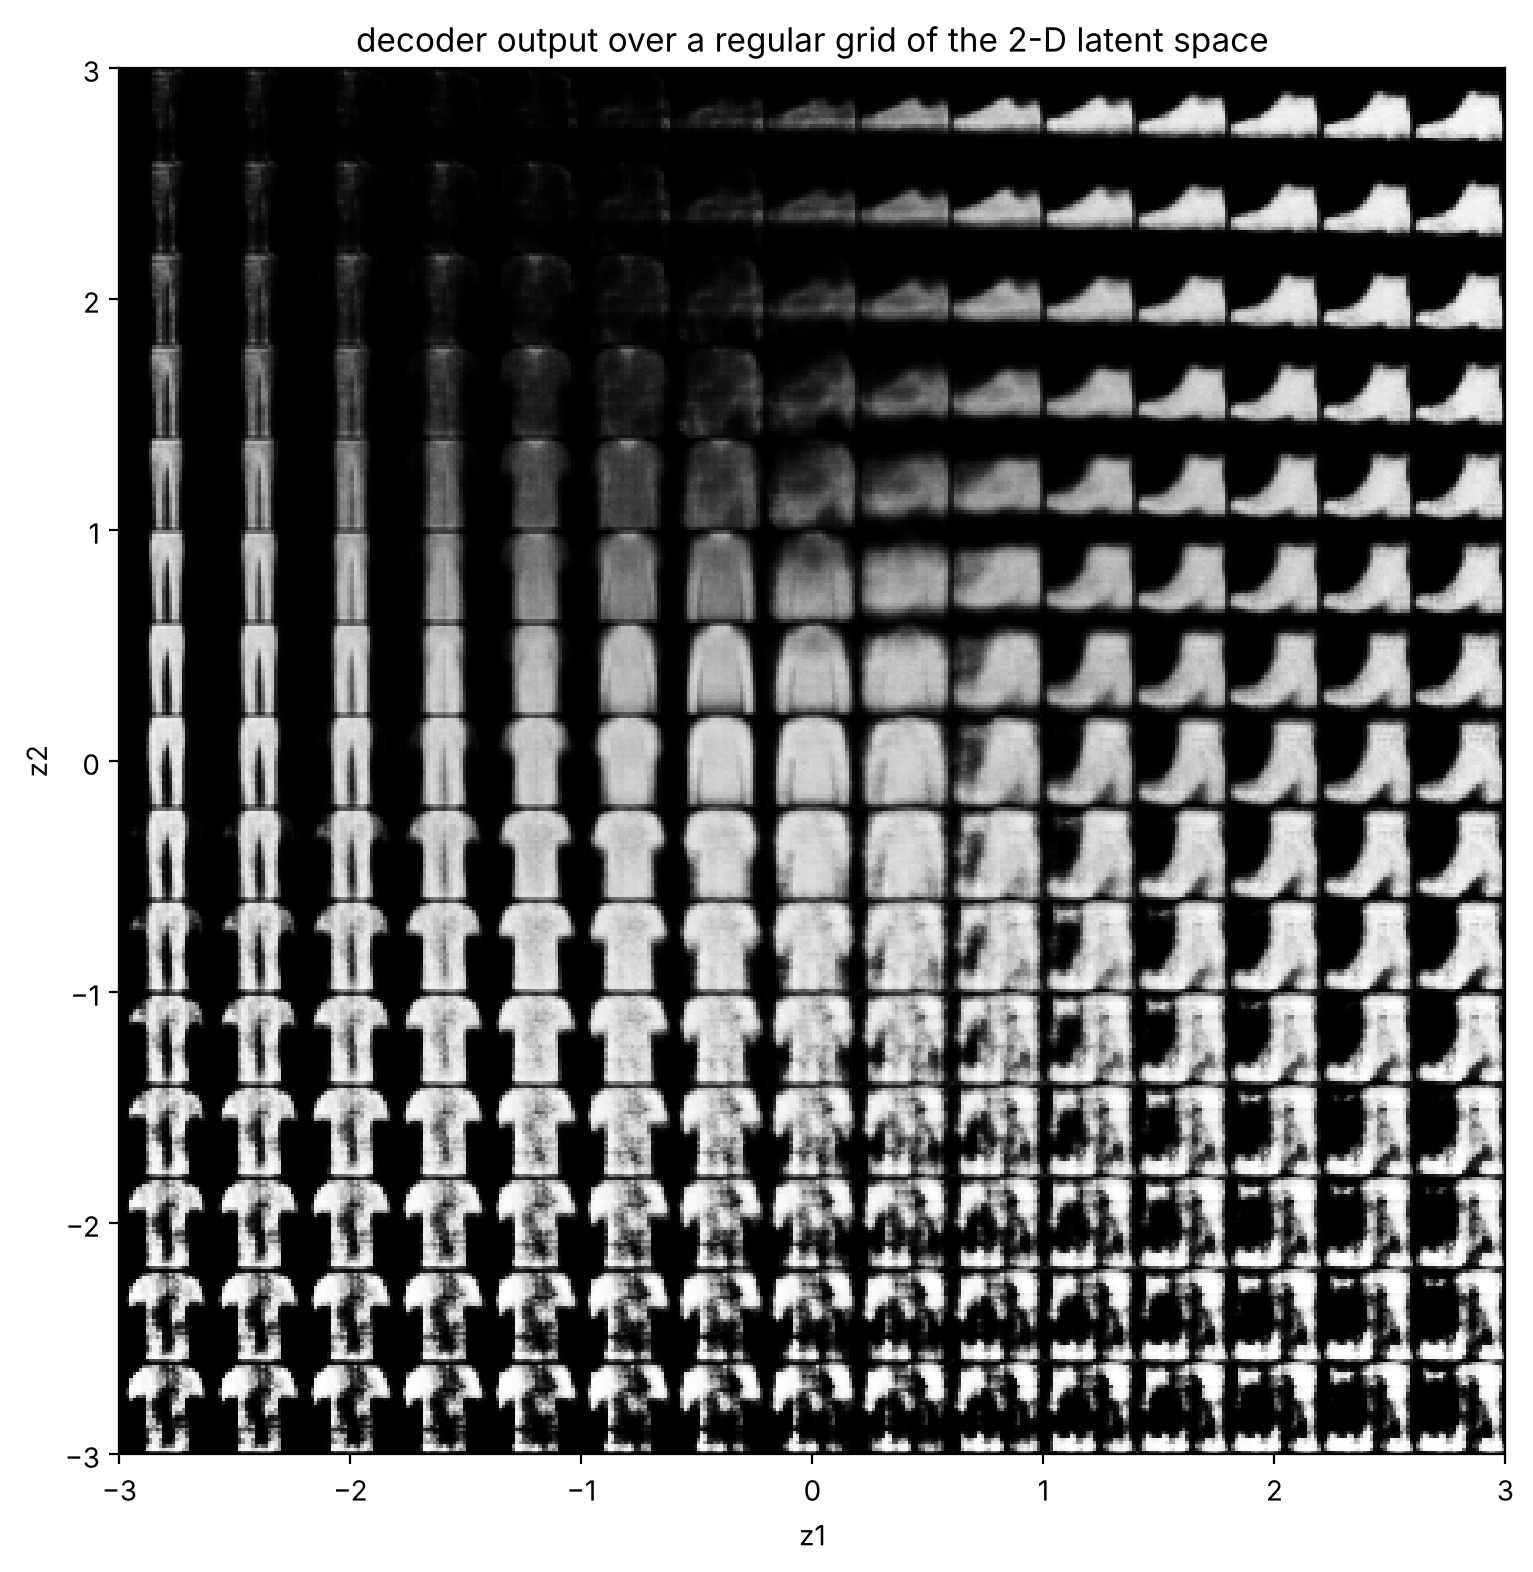

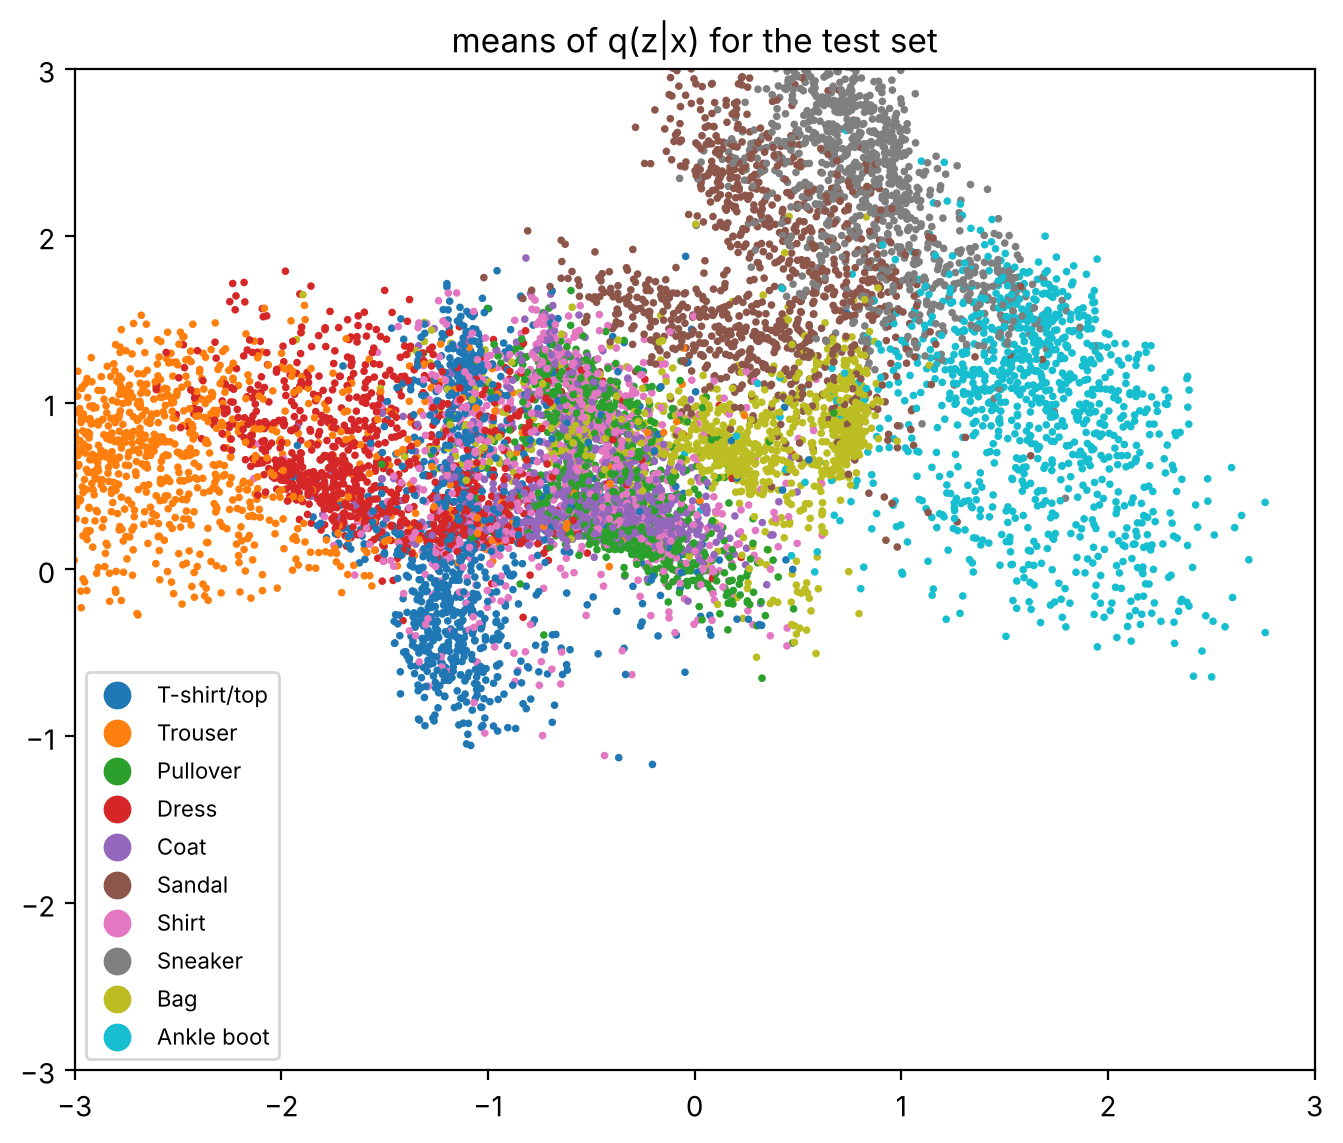

In [3]:
torch.manual_seed(0)
vae2 = train_vae(VAE(latent=2))
vae2.eval()

n = 15
grid = torch.linspace(-3, 3, n)
z = torch.stack([torch.stack([gx, -gy]) for gy in grid for gx in grid]).to(device)   # top row = large z2
with torch.no_grad():
    imgs = vae2.decoder(z).cpu().view(n, n, 28, 28)
canvas = imgs.permute(0, 2, 1, 3).reshape(n * 28, n * 28)
plt.figure(figsize=(9, 9))
plt.imshow(canvas, cmap='gray', extent=[-3, 3, -3, 3]); plt.xlabel('z1'); plt.ylabel('z2')
plt.title('decoder output over a regular grid of the 2-D latent space'); plt.show()

# where do the real test images land?
with torch.no_grad():
    mus, ys = [], []
    for x, y in test_loader:
        mus.append(vae2.encoder(x.to(device)).chunk(2, dim=1)[0].cpu()); ys.append(y)
mus, ys = torch.cat(mus).numpy(), torch.cat(ys).numpy()
plt.figure(figsize=(8, 6.5))
sc = plt.scatter(mus[:, 0], mus[:, 1], c=ys, cmap='tab10', s=3)
plt.legend(handles=sc.legend_elements()[0], labels=CLASSES, fontsize=8, markerscale=1.5)
plt.xlim(-3, 3); plt.ylim(-3, 3); plt.title('means of q(z|x) for the test set'); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

در «نقشه» فضای نهان، تصاویر به‌طور **پیوسته** از یک نوع به نوع دیگر تغییر شکل می‌دهند (مثلاً از کفش ورزشی به نیم‌بوت و از پیراهن به کت)، و بیشتر بازهٔ $[-3, 3]^2$ تصاویر معنادار تولید می‌کند؛ فقط گوشه‌های دور از مبدأ، که دادهٔ واقعی کمی به آنجا نگاشت شده، نویزی‌ترند. این نتیجهٔ مستقیم جملهٔ KL است که کدها را به سمت $\mathcal{N}(0, I)$ می‌کشد. نمودار دوم نشان می‌دهد هر کلاس ناحیهٔ خودش را دارد و نواحی تقریباً کل دایرهٔ اطراف مبدأ را پر کرده‌اند. با فقط دو بعد، بازسازی‌ها تار است؛ ارزش این آزمایش در دیدن ساختار فضای نهان است.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

**β-VAE:** VAE را با $\beta = 0.1$ و $\beta = 4$ آموزش دهید. کیفیت بازسازی و کیفیت نمونه‌های تولیدی چه تغییری می‌کند؟ چرا؟

</div>

beta = 0.1: test reconstruction MSE 0.01171


beta = 1.0: test reconstruction MSE 0.01587


beta = 4.0: test reconstruction MSE 0.02443


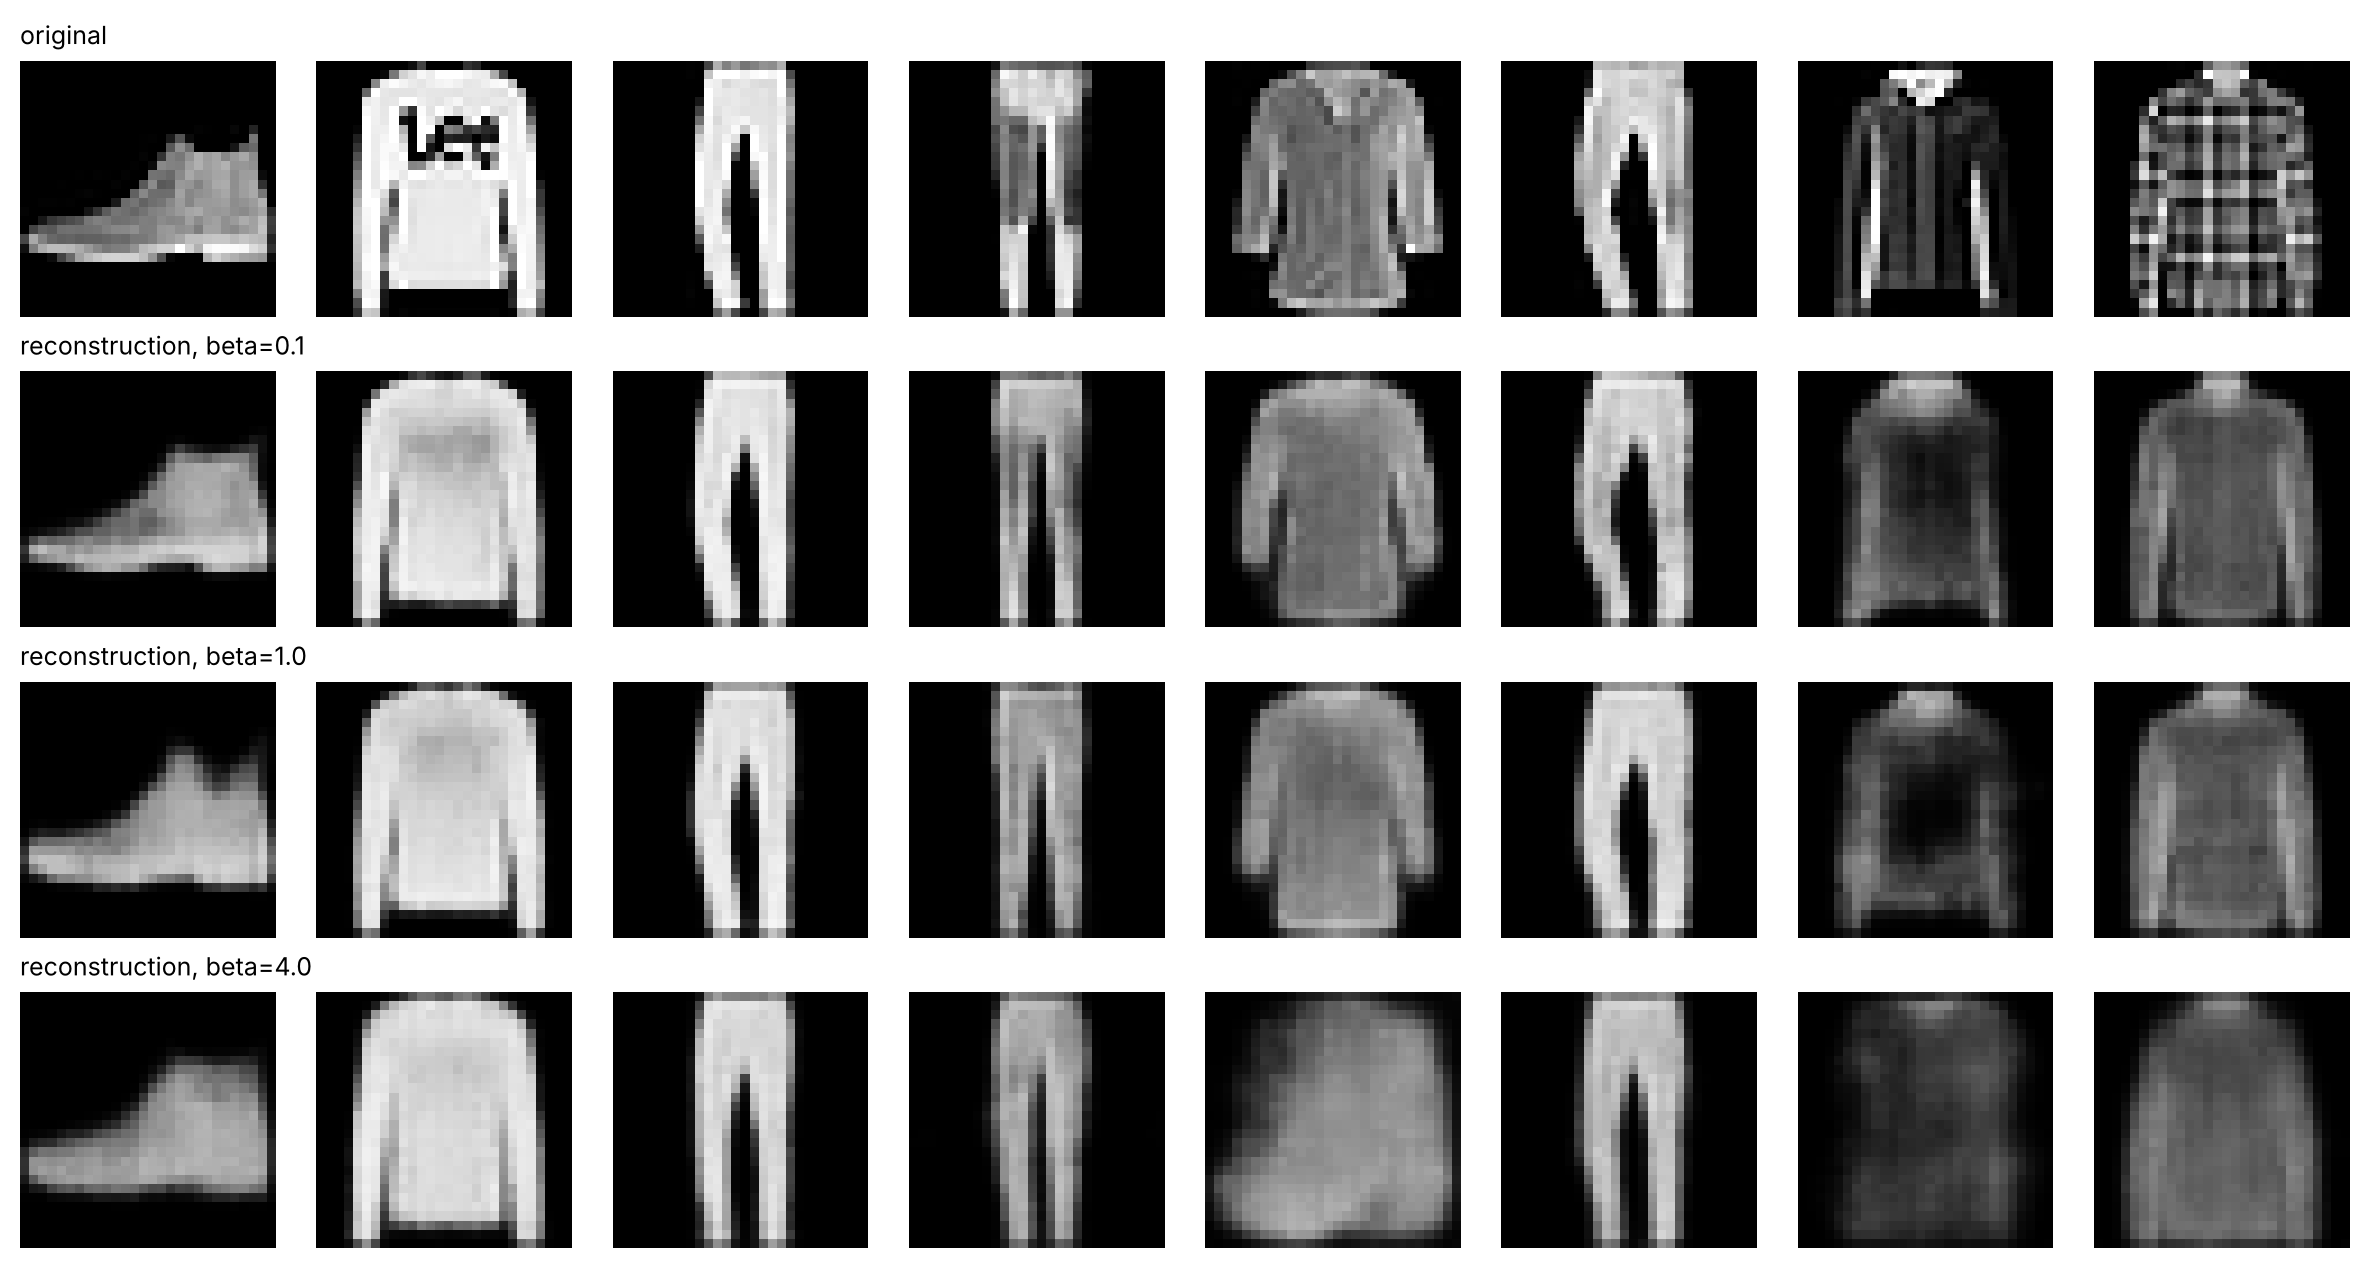

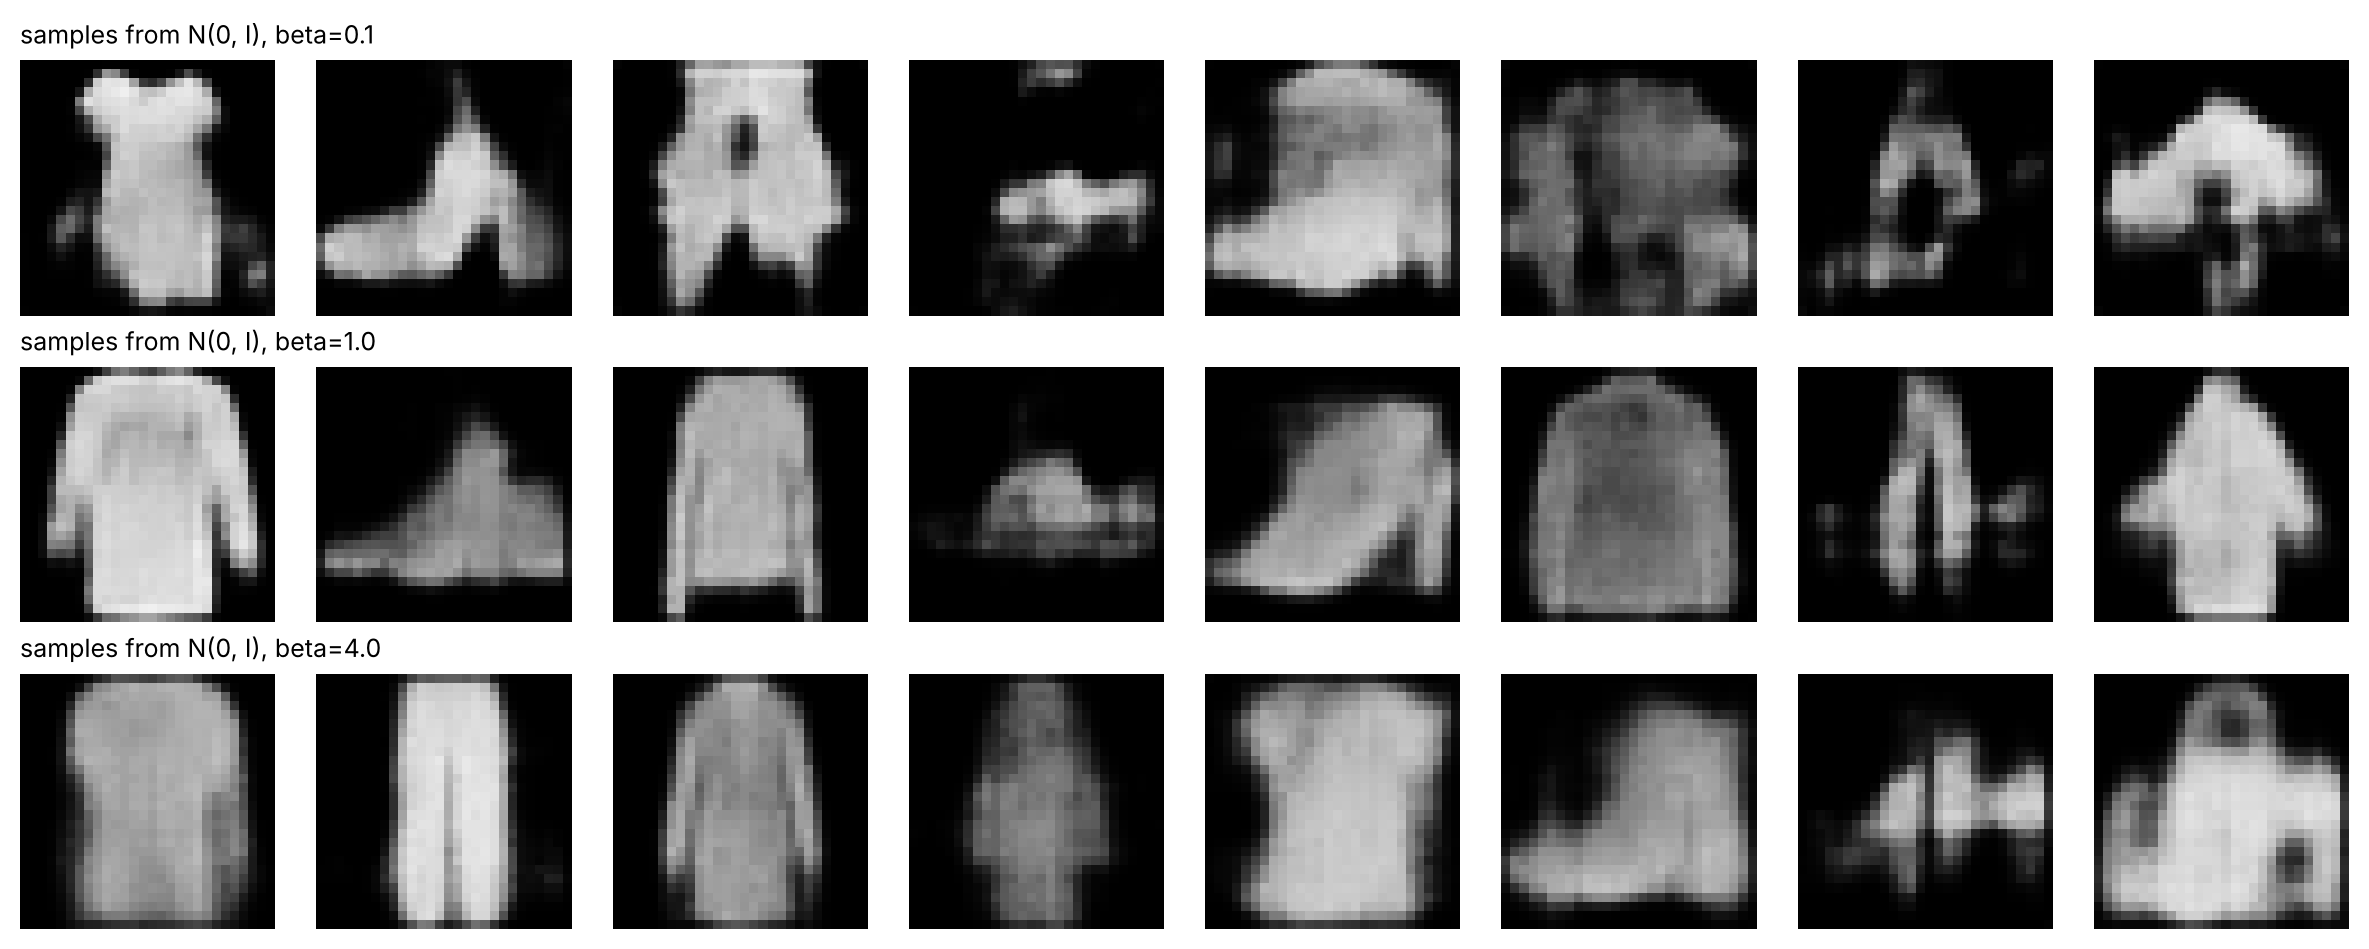

In [4]:
vaes = {}
for beta in (0.1, 1.0, 4.0):
    torch.manual_seed(0)
    vaes[beta] = train_vae(VAE(16), beta=beta)
    print(f'beta = {beta}: test reconstruction MSE {test_mse(vaes[beta]):.5f}')

torch.manual_seed(1)
z = torch.randn(8, 16, device=device)
with torch.no_grad():
    recon_rows = [x_test] + [vaes[b].eval()(x_test)[0] for b in vaes]
    sample_rows = [vaes[b].decoder(z) for b in vaes]
show_rows(recon_rows, ['original'] + [f'reconstruction, beta={b}' for b in vaes])
show_rows(sample_rows, [f'samples from N(0, I), beta={b}' for b in vaes])

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- **$\beta = 0.1$:** جریمهٔ KL ضعیف است و مدل شبیه Autoencoder معمولی رفتار می‌کند. بازسازی‌ها دقیق‌ترند، اما کدها از $\mathcal{N}(0, I)$ فاصله دارند. نمونه‌گیری از توزیع استاندارد به نواحی‌ای می‌افتد که Decoder ندیده است، پس نمونه‌های تولیدی بیشتر **ناهنجار و درهم** هستند.
- **$\beta = 4$:** جریمهٔ KL قوی است و فضای نهان بسیار منظم و هموار می‌شود. نمونه‌ها «معقول» ولی **تار و کلی** هستند و بازسازی‌ها جزئیات زیادی را از دست می‌دهند؛ مدل ترجیح می‌دهد اطلاعات کمتری در $\mathbf{z}$ نگه دارد.

این همان مصالحهٔ **نرخ و اعوجاج (Rate–Distortion)** است. β-VAE (Higgins et al., 2017) با $\beta > 1$ معمولاً ابعاد نهان «تفکیک‌شده‌تر» (Disentangled) یاد می‌گیرد، به قیمت کیفیت بازسازی.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

در تشخیص ناهنجاری، Autoencoder را فقط روی یک کلاس (مثلاً Trouser) آموزش دهید و ROC-AUC را برای تشخیص بقیه کلاس‌ها حساب کنید.

</div>

In [5]:
TROUSER = 1
idx = (train_set.targets == TROUSER).nonzero().squeeze().tolist()
trouser_loader = DataLoader(Subset(train_set, idx), batch_size=128, shuffle=True, num_workers=2)
torch.manual_seed(0)
trouser_ae = train_ae(Autoencoder(16), loader=trouser_loader, epochs=3 * EPOCHS)   # 6,000 images: more epochs

trouser_ae.eval()
errs, ys = [], []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        errs.append(((trouser_ae(x) - x) ** 2).mean(dim=(1, 2, 3)).cpu()); ys.append(y)
err, y = torch.cat(errs).numpy(), torch.cat(ys).numpy()
normal = y == TROUSER
print(f'overall ROC-AUC (trouser vs everything else): {roc_auc_score(~normal, err):.3f}')
for c in range(10):
    if c != TROUSER:
        mask = normal | (y == c)
        print(f'  trouser vs {CLASSES[c]:12}: AUC {roc_auc_score(y[mask] == c, err[mask]):.3f}')

overall ROC-AUC (trouser vs everything else): 0.987
  trouser vs T-shirt/top : AUC 0.980
  trouser vs Pullover    : AUC 0.989
  trouser vs Dress       : AUC 0.956
  trouser vs Coat        : AUC 0.988
  trouser vs Sandal      : AUC 0.995
  trouser vs Shirt       : AUC 0.981
  trouser vs Sneaker     : AUC 0.997
  trouser vs Bag         : AUC 0.997
  trouser vs Ankle boot  : AUC 0.999


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

به‌جای سه کلاس کفش، این بار فقط یک کلاس (شلوار) «عادی» است. AUC کلی معمولاً بسیار بالاست؛ شلوار شکل بسیار مشخصی دارد (دو ستون عمودی) و Autoencoder اشیای دیگر را بد بازسازی می‌کند. AUC به تفکیک کلاس آموزنده‌تر است: کلاس‌هایی که از نظر شکل به شلوار نزدیک‌ترند (مثلاً لباس بلند Dress) سخت‌تر تشخیص داده می‌شوند. کفش و کیف با شکل کاملاً متفاوت بسیار راحت تشخیص داده می‌شوند. **محدودیت مهم:** خطای بازسازی فقط تفاوت **ظاهری** را می‌سنجد. ناهنجاری‌ای که ظاهری شبیه دادهٔ عادی دارد از این روش پنهان می‌ماند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۵

Denoising Autoencoder را برای نوع دیگری از خرابی آموزش دهید: پاک کردن یک مربع ۱۰×۱۰ تصادفی از تصویر (**Inpainting**).

</div>

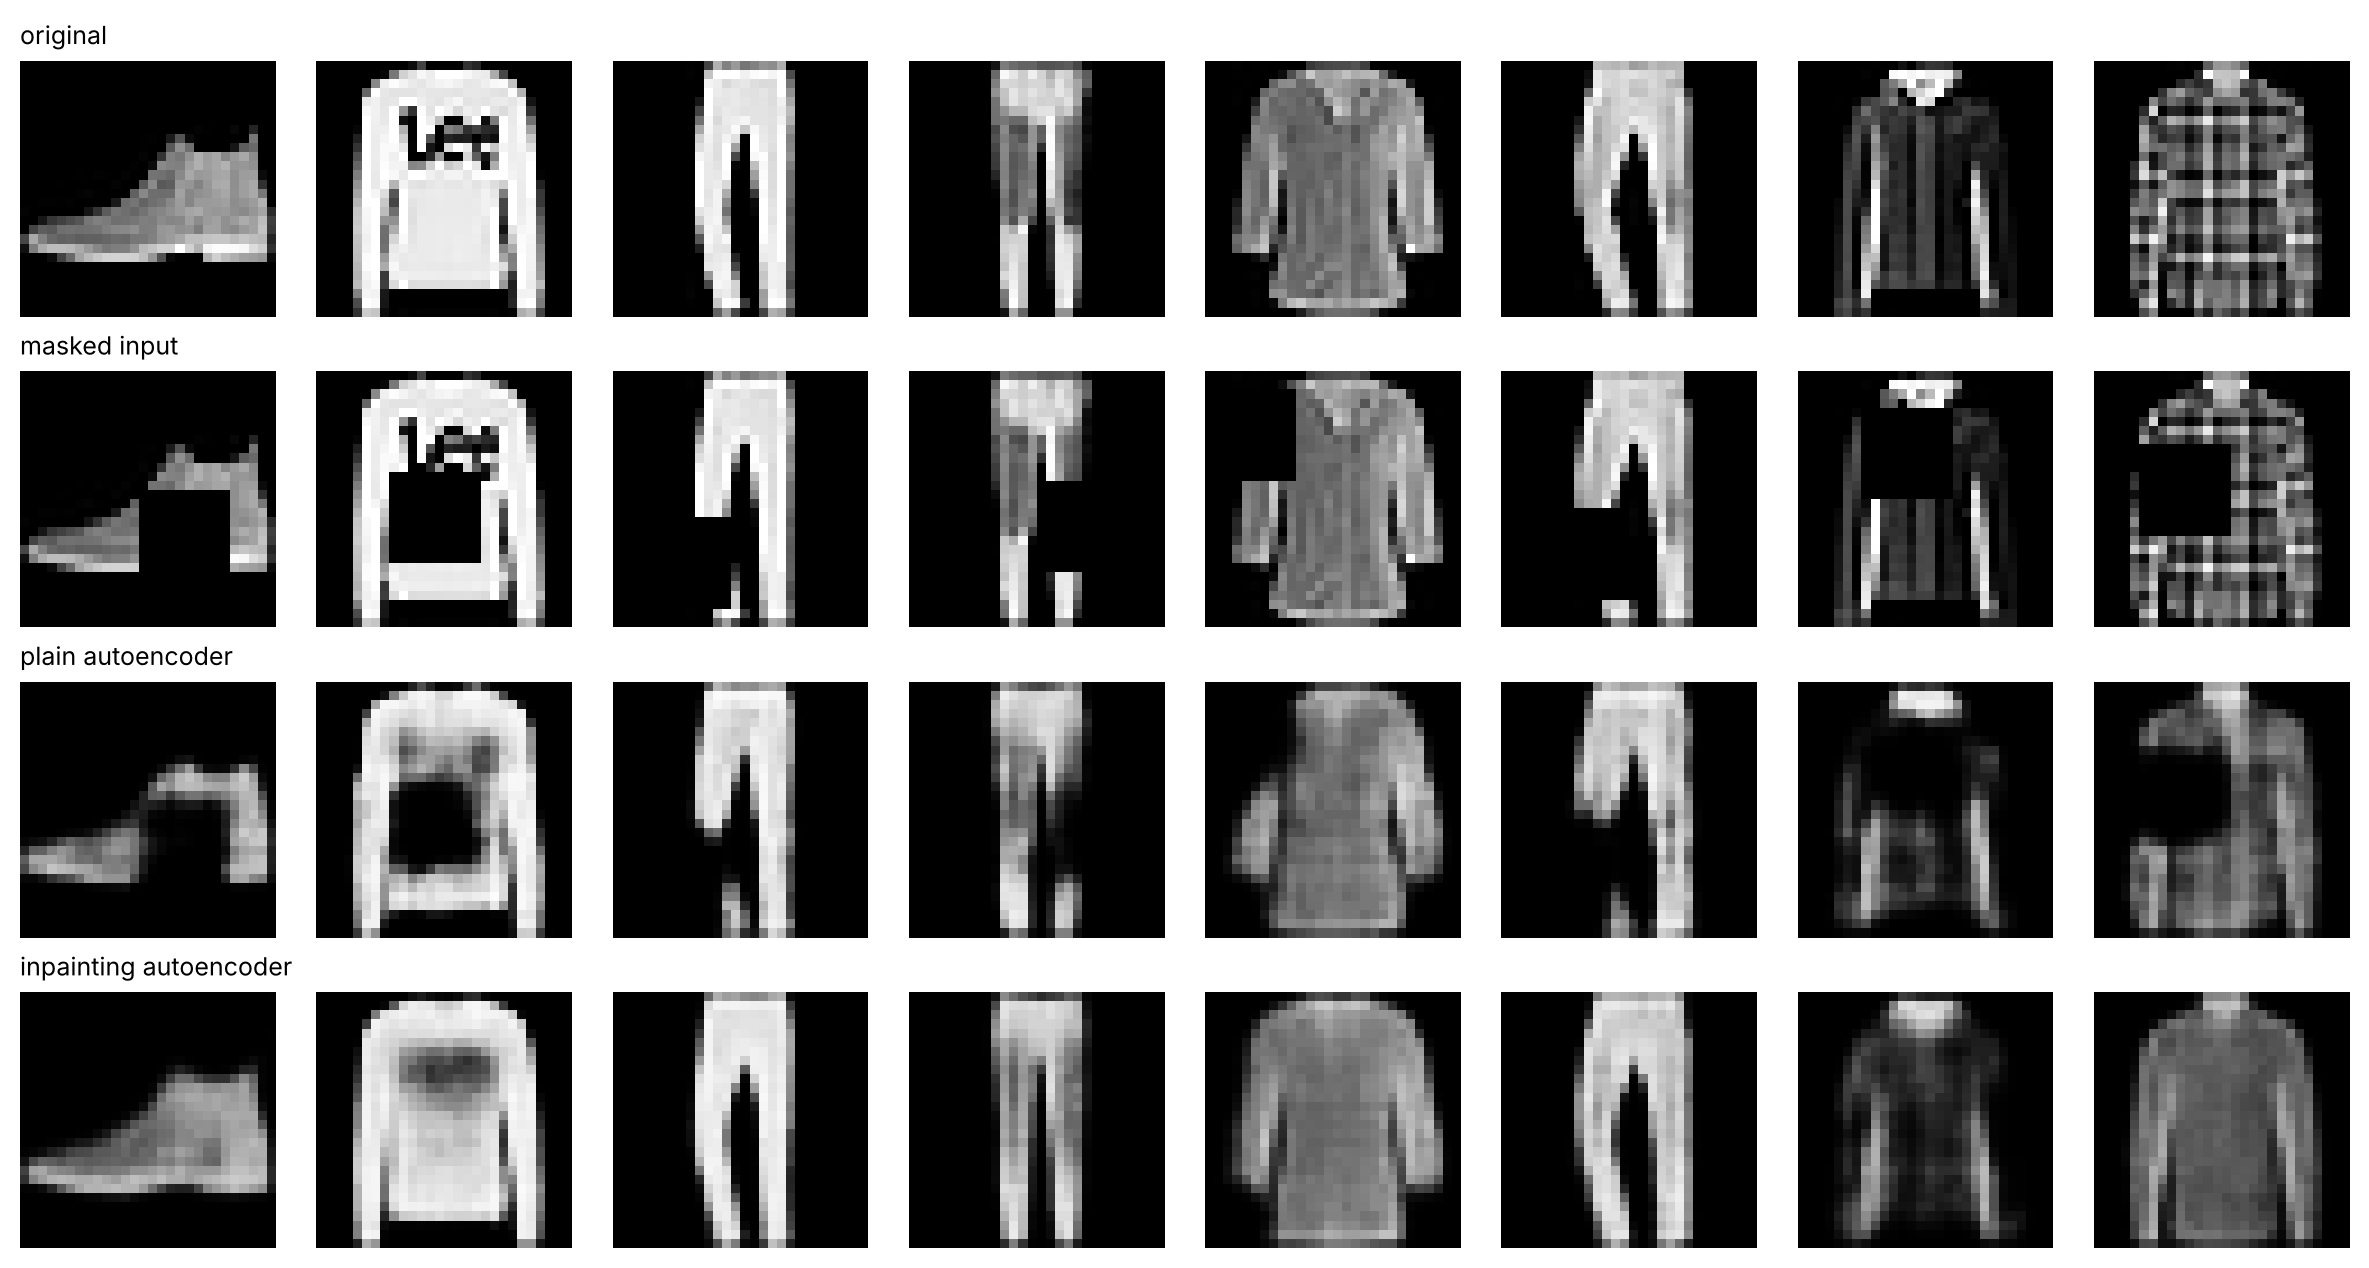

test MSE on masked images | plain AE 0.04309 | inpainting AE 0.01002


In [6]:
def random_square_mask(x, size=10):
    """Erase one random size x size square in every image (set it to zero)."""
    x = x.clone()
    B = x.shape[0]
    r = torch.randint(0, 28 - size + 1, (B,))
    c = torch.randint(0, 28 - size + 1, (B,))
    for i in range(B):
        x[i, :, r[i]:r[i] + size, c[i]:c[i] + size] = 0.0
    return x


torch.manual_seed(0)
inpainter = train_ae(Autoencoder(64), corrupt=random_square_mask)
plain_ae = models_by_latent[64]                         # trained on clean images only (exercise 1)

torch.manual_seed(3)
masked = random_square_mask(x_test)
with torch.no_grad():
    show_rows([x_test, masked, plain_ae.eval()(masked), inpainter.eval()(masked)],
              ['original', 'masked input', 'plain autoencoder', 'inpainting autoencoder'])

    se_plain = se_inp = 0.0
    torch.manual_seed(4)
    for x, _ in test_loader:
        x = x.to(device); m = random_square_mask(x)
        se_plain += F.mse_loss(plain_ae(m), x, reduction='sum').item()
        se_inp += F.mse_loss(inpainter(m), x, reduction='sum').item()
print(f'test MSE on masked images | plain AE {se_plain / (len(test_set) * 784):.5f} | inpainting AE {se_inp / (len(test_set) * 784):.5f}')

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

Autoencoder معمولی هرگز تصویر با «سوراخ» ندیده است و تلاش می‌کند همان ورودی را بازسازی کند؛ پس مربع سیاه را تا حد زیادی در خروجی نگه می‌دارد. مدل Inpainting یاد گرفته است که ناحیهٔ پاک‌شده اطلاعاتی ندارد و آن را بر اساس **بقیهٔ تصویر** (شکل کلی شیء) پر کند. نتیجه کمی تار است ولی شکل را منطقی ادامه می‌دهد و خطای آن روی تصاویر ماسک‌شده به‌وضوح کمتر است. همین ایده، یعنی بازسازی بخش‌های پنهان‌شده، در مقیاس بزرگ پایهٔ روش‌های خودنظارتی مثل **Masked Autoencoder** (He et al., 2022) برای تصویر و **BERT** برای متن است.

</div>